First, I read in the data files

In [39]:
# Data libraries

import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
from matplotlib import image as mpimg
import seaborn as sns

# sklearn modules
import sklearn

df_avg = pd.read_csv("csv_files/avg_river_levels.csv")
df_min = pd.read_csv("csv_files/min_river_levels.csv")
df_max = pd.read_csv("csv_files/max_river_levels.csv")
df_locs = pd.read_csv("csv_files/monitoring_locations.csv")
df_avg.head()



,County,Station_Name,Observation_ID,05/10/2014,06/10/2014,07/10/2014,08/10/2014,09/10/2014,10/10/2014,13/10/2014,...,29/09/2026,30/09/2026,01/10/2026,02/10/2026,03/10/2026,04/10/2026,05/10/2026,06/10/2026,07/10/2026,08/10/2026
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.133,0.152,0.169,0.143,0.136,0.130,0.126,0.120,0.120,0.120
1,aberdeenshire,"Dee (Grampian), Mar Lodge",aberdeenshire__dee-grampian-mar-lodge__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.721,0.971,0.849,0.799,0.861,0.752,0.727,0.695,0.677,0.669
2,aberdeenshire,"Dee (Grampian), Park",aberdeenshire__dee-grampian-park__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.934,0.973,1.264,0.990,1.054,0.988,0.918,0.887,0.854,0.836
3,aberdeenshire,"Dee (Grampian), Polhollick",aberdeenshire__dee-grampian-polhollick__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.483,0.704,0.683,0.530,0.676,0.530,0.496,0.460,0.438,0.427
4,aberdeenshire,"Dee (Grampian), Woodend",aberdeenshire__dee-grampian-woodend__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.578,0.700,0.861,0.645,0.739,0.642,0.583,0.547,0.514,0.495


In [ ]:
#df combined 
# Merge into one useful dataframe 
id_cols = ['County', 'Station_Name', 'Observation_ID']
date_cols = [c for c in df_avg.columns if c not in id_cols]

def melt_river_data(df, value_name):
    """ Converts wide format (dates as columns) to long format (dates as rows)"""
    melted = df.melt(
        id_vars=id_cols, 
        value_vars=date_cols, 
        var_name='Date', 
        value_name=value_name
    )
    return melted

df_avg_long = melt_river_data(df_avg, 'Avg_Level')
df_min_long = melt_river_data(df_min, 'Min_Level')
df_max_long = melt_river_data(df_max, 'Max_Level')

# Merge long format df_min and long format df_avg
df_combined = pd.merge(
    df_avg_long, 
    df_min_long, 
    on=id_cols + ['Date'],  
    how='outer'             
)

# Then merge result with long format df_max 
df_combined = pd.merge(
    df_combined, 
    df_max_long, 
    on=id_cols + ['Date'], 
    how='outer'
)

# Finally merge with df_locs
df_combined = pd.merge(
    df_combined,
    df_locs,
    on=id_cols,
)

df_combined.head()

Then I plotted a map showing the locations of the stations, then overlayed this on a map of Scotland using https://kepler.gl/demo? 


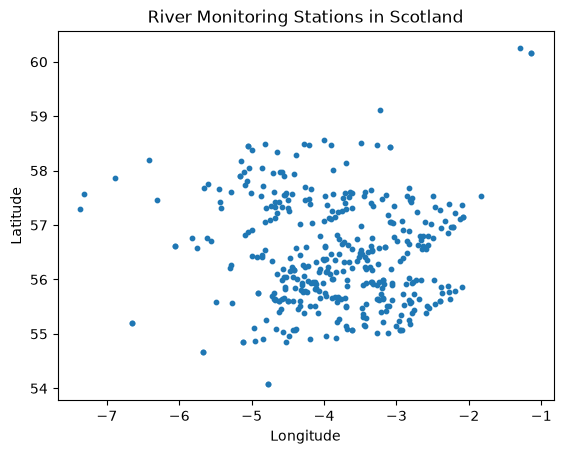

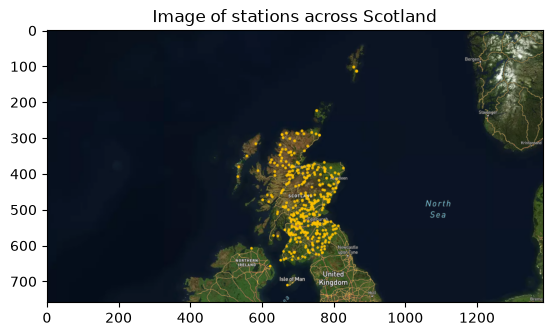

In [9]:
#map of the stations

plt.scatter(df_locs["Longitude"], df_locs["Latitude"], s=10)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("River Monitoring Stations in Scotland")
plt.show()


#plotting on a map of scotland
plt.title("Image of stations across Scotland")

image = mpimg.imread("kepler.gl.png")
plt.imshow(image)
plt.show()

then we investigated missing values in the data.we plotted  timeseries to investigate how missing data changes over time, and found that the vast majority of data was missing until ??? 2018, so we cleaned the data by getting rid of ??? imputing ???? idk guys fill this in  xxxxx then i plotted a histogram to see how many stations were missing certain amounts of data, and then created a heatmap to show if the stations with lots of missing data happened to be concentrated in a certain area. Then i coloured the map of scotland by the amount of missing data to see if this made a difference. 

NOTE will need to redo this and create heatmap and histogram again once we have a new dataset. 

avg is missing 525,877 values (30.61%)
min is missing 525,877 values (30.61%)
max is missing 525,877 values (30.61%)


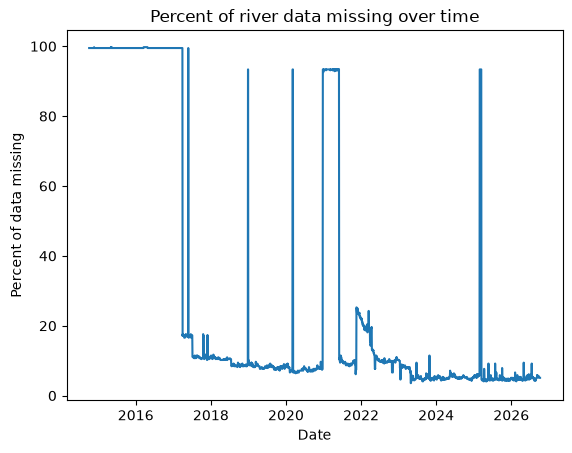

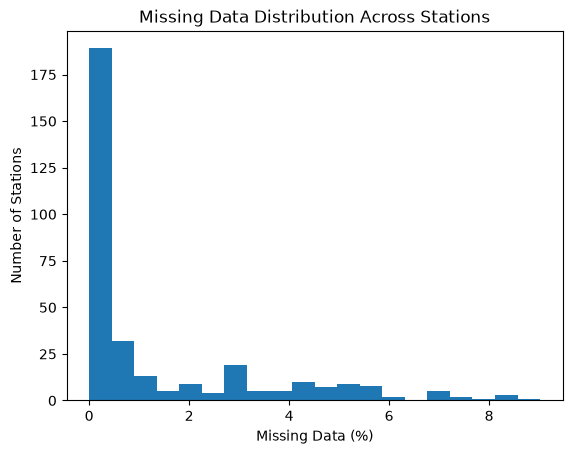

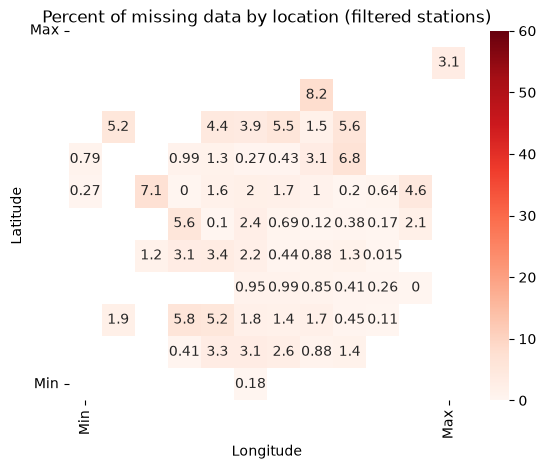

Observation_ID
aberdeenshire__bogie-redcraig__obs1               0.000000
aberdeenshire__dee-grampian-mar-lodge__obs1       0.151837
aberdeenshire__dee-grampian-park__obs1            0.030367
aberdeenshire__dee-grampian-polhollick__obs1      0.091102
aberdeenshire__dee-grampian-woodend__obs1         0.212572
                                                    ...   
wigtown__port-erin-wigtown__obs2                  3.310052
wigtown__portpatrick-wigtown-tidal-level__obs2    3.067112
wigtown__portpatrick-wigtown__obs1                3.067112
wigtown__water-of-luce-airyhemming__obs1          1.973884
wigtown__water-of-minnoch-minnoch-bridge__obs1    0.242940
Length: 329, dtype: float64

In [25]:
# Load data  

# Merge into one useful dataframe 
id_cols = ['County', 'Station_Name', 'Observation_ID']
date_cols = [c for c in df_avg.columns if c not in id_cols]

def melt_river_data(df, value_name):
    """ Converts wide format (dates as columns) to long format (dates as rows)"""
    melted = df.melt(
        id_vars=id_cols, 
        value_vars=date_cols, 
        var_name='Date', 
        value_name=value_name
    )
    return melted

df_avg_long = melt_river_data(df_avg, 'Avg_Level')
df_min_long = melt_river_data(df_min, 'Min_Level')
df_max_long = melt_river_data(df_max, 'Max_Level')

# Merge long format df_min and long format df_avg
df_combined = pd.merge(
    df_avg_long, 
    df_min_long, 
    on=id_cols + ['Date'],  
    how='outer'             
)

# Then merge result with long format df_max 
df_combined = pd.merge(
    df_combined, 
    df_max_long, 
    on=id_cols + ['Date'], 
    how='outer'
)

# Finally merge with df_locs
df_combined = pd.merge(
    df_combined,
    df_locs,
    on=id_cols,
)

df_combined.head()

for name, df in [("avg", df_avg), ("min", df_min), ("max", df_max)]:
    missing = df.isna().sum().sum()
    total = df.size
    print(f"{name} is missing {missing:,} values ({missing / total * 100:.2f}%)")


#plotting the missing values againt date
missing = df_avg.iloc[:, 3:].isna().mean(axis=0) * 100

plt.plot(pd.to_datetime(missing.index, dayfirst=True), missing)
plt.xlabel("Date")
plt.ylabel("Percent of data missing")
plt.title("Percent of river data missing over time")
plt.show()


df_combined['Date'] = pd.to_datetime(df_combined['Date'], format='%d/%m/%Y')


#Work withdata in wide form

dates = pd.to_datetime(df_avg.columns[3:], dayfirst=True)   # dd/mm/yyyy strings
vals = df_avg.iloc[:, 3:].copy()
vals.columns = dates
vals.index = df_avg["Observation_ID"]        # or Station_Name, if it's unique
vals = vals.T                                # rows = dates, columns = stations

# full daily data with NA rows where gaps were 
vals = vals.reindex(pd.date_range(vals.index.min(), vals.index.max(), freq="D")) 

# drop bigoutage days 
good = vals[vals.isna().mean(axis=1) <= 0.5] # compute for each date fraction of stations missing,get rid of dates with more than 50% missing

# drop stations that are missing too much of what's left
miss = good.isna().mean()
keep = miss.index[miss <= 0.1]        
filtered = good[keep]

miss_fil = filtered.isna().mean() * 100

#histogram 
plt.hist(miss_fil, bins=20)
plt.xlabel("Missing Data (%)")
plt.ylabel("Number of Stations")
plt.title("Missing Data Distribution Across Stations")
plt.show()

#heatmap
df_map = df_locs.copy()
df_map.index = df_avg["Observation_ID"]          
df_map["Missing"] = miss_fil          

df_map["Latitude"] = pd.cut(df_map["Latitude"], bins=12, ordered=True)
df_map["Longitude"] = pd.cut(df_map["Longitude"], bins=12)

heatmap_data = df_map.pivot_table(values="Missing", index="Latitude",
                                  columns="Longitude", observed=False)
sns.heatmap(heatmap_data, annot=True, cmap="Reds", vmin=0, vmax=60)
plt.title("Percent of missing data by location (filtered stations)")
plt.xticks([0.5, 11.5], ["Min", "Max"])
plt.yticks([0.5, 11.5], ["Min", "Max"])
plt.gca().invert_yaxis()
plt.show()

miss_fil


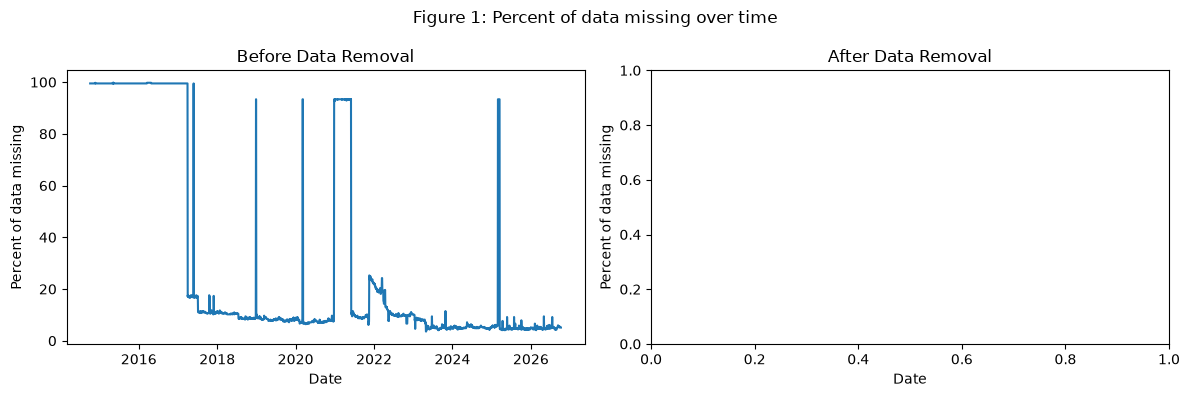

In [44]:

#missing value investigations

#checking the locations of missing data is the same for min max avg
min_missing = df_min.iloc[:, 3:].isna()
max_missing = df_max.iloc[:, 3:].isna()
avg_missing = df_avg.iloc[:, 3:].isna()

missing = df_avg.isna().sum().sum()
total = df_avg.size
#print(f"Each dataset is missing {missing:,} values ({missing / total * 100:.2f}%)")


#plotting the missing values againt date
missing = df_avg.iloc[:, 3:].isna().mean(axis=0) * 100
import matplotlib.pyplot as plt
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

ax[0].plot(pd.to_datetime(missing.index, dayfirst=True), missing)
ax[0].set_xlabel("Date")
ax[0].set_ylabel("Percent of data missing")
ax[0].set_title("Before Data Removal")

ax[1].set_xlabel("Date")
ax[1].set_ylabel("Percent of data missing")
ax[1].set_title("After Data Removal")

plt.suptitle("Figure 1: Percent of data missing over time")
plt.tight_layout()
plt.savefig('missing_data_over_time.png', bbox_inches='tight')
plt.show()

In [29]:
filtered

Observation_ID,aberdeenshire__bogie-redcraig__obs1,aberdeenshire__dee-grampian-mar-lodge__obs1,aberdeenshire__dee-grampian-park__obs1,aberdeenshire__dee-grampian-polhollick__obs1,aberdeenshire__dee-grampian-woodend__obs1,aberdeenshire__deveron-avochie__obs1,aberdeenshire__deveron-huntly-gs__obs1,aberdeenshire__don-alford__obs1,aberdeenshire__don-culfork__obs1,aberdeenshire__don-haughton__obs1,...,wigtown__bladnoch-low-malzie__obs1,wigtown__cree-newton-stewart__obs1,wigtown__cree-wheeb-bridge__obs1,wigtown__piltanton-burn-barsolus__obs1,wigtown__port-erin-wigtown-tidal-level__obs1,wigtown__port-erin-wigtown__obs2,wigtown__portpatrick-wigtown-tidal-level__obs2,wigtown__portpatrick-wigtown__obs1,wigtown__water-of-luce-airyhemming__obs1,wigtown__water-of-minnoch-minnoch-bridge__obs1
2017-03-31,0.221,1.057,1.045,0.772,0.740,0.284,0.525,0.741,0.065,2.366,...,1.603,2.106,1.047,0.686,NaN,NaN,NaN,NaN,1.181,1.641
2017-04-01,0.221,0.867,1.205,0.695,0.892,0.283,0.522,0.749,0.066,2.376,...,1.338,1.278,0.695,0.569,NaN,NaN,NaN,NaN,0.700,0.918
2017-04-02,0.220,0.811,1.087,0.598,0.753,0.283,0.523,0.750,0.074,2.388,...,0.933,0.877,0.561,0.523,NaN,NaN,NaN,NaN,0.553,0.706
2017-04-03,0.212,0.747,0.990,0.535,0.681,0.277,0.517,0.736,0.062,2.364,...,0.823,0.752,0.498,0.505,NaN,NaN,NaN,NaN,0.500,0.641
2017-04-04,0.208,0.738,0.938,0.514,0.638,0.276,0.516,0.727,0.057,2.349,...,0.800,0.942,0.492,0.494,NaN,NaN,NaN,NaN,0.504,0.816
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-04,0.130,0.752,0.988,0.530,0.642,0.224,0.462,0.643,0.142,2.204,...,0.864,0.896,0.548,0.594,0.252,2.993,2.443,0.643,0.487,0.699
2026-10-05,0.126,0.727,0.918,0.496,0.583,0.220,0.451,0.629,0.136,2.188,...,0.787,0.782,0.500,0.533,0.274,3.021,2.410,0.615,0.446,0.659
2026-10-06,0.120,0.695,0.887,0.460,0.547,0.214,0.440,0.620,0.130,2.175,...,0.746,0.742,0.477,0.520,0.313,3.046,2.241,0.440,0.423,0.647
2026-10-07,0.120,0.677,0.854,0.438,0.514,0.210,0.437,0.615,0.130,2.170,...,0.713,0.671,0.453,0.551,0.770,3.520,2.987,1.187,0.451,0.607


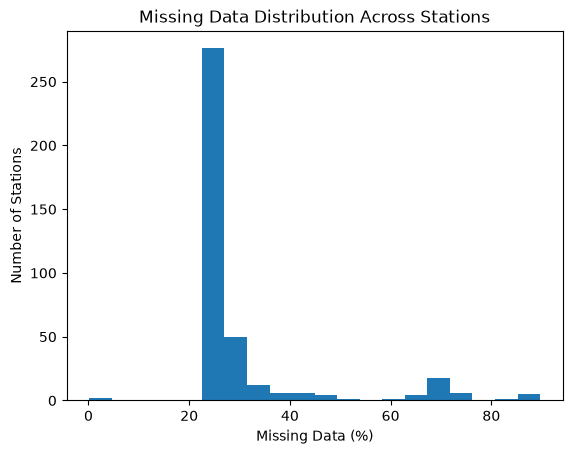

In [11]:
#histograms of the missing values  - redo with new dataset
missing_station = df_avg.iloc[:, 3:].isna().mean(axis=1) * 100

plt.hist(missing_station, bins=20)
plt.xlabel("Missing Data (%)")
plt.ylabel("Number of Stations")
plt.title("Missing Data Distribution Across Stations")
plt.show()

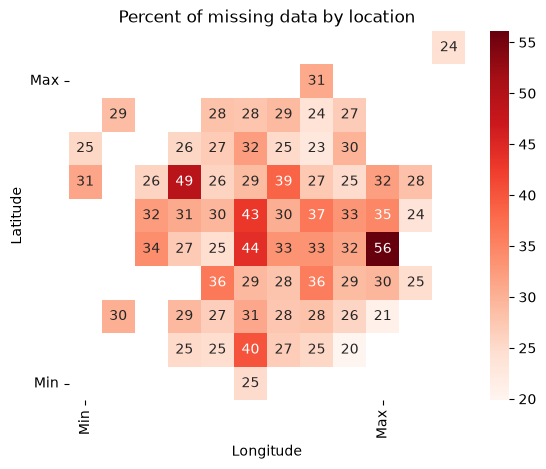

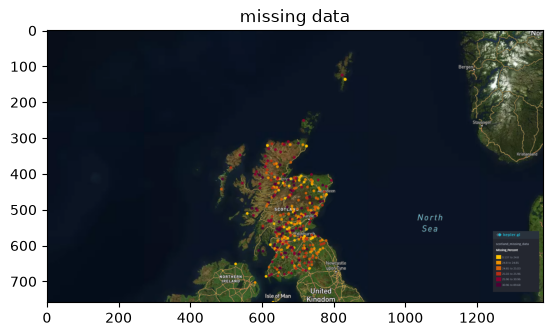

In [12]:
#https://seaborn.pydata.org/generated/seaborn.heatmap.html as a reference and the week 1 workshop
#https://pandas.pydata.org/docs/reference/api/pandas.cut.html

#colour map
missing_station = df_avg.iloc[:, 3:].isna().mean(axis=1) * 100

df_map = df_locs.copy()
df_map["Missing"] = missing_station

#sorting into categorical variables
df_map["Latitude"] = pd.cut(df_map["Latitude"], bins=12, ordered = True)
df_map["Longitude"] = pd.cut(df_map["Longitude"], bins=12)

heatmap_data = df_map.pivot_table(values="Missing",index="Latitude",columns="Longitude")
sns.heatmap(heatmap_data, annot=True, cmap = 'Reds')
plt.title("Percent of missing data by location")
plt.xticks([0.5, 9.5], ["Min", "Max"])
plt.yticks([0.5, 9.5], ["Min", "Max"])
plt.gca().invert_yaxis()
plt.show()

#adding a column of the missing stations 

df_map = df_locs.merge(df_avg[["Observation_ID"]].assign(Missing_Percent=missing_station),on="Observation_ID")
df_map.to_csv("scotland_missing_data.csv", index=False)
df_map["Missing_Percent"] = pd.to_numeric(df_map["Missing_Percent"])
df_map.to_csv("scotland_missing_data.csv", index=False)

#creating this on an actual map 
plt.title("missing data")
image = mpimg.imread("missing_data_heatmap.png")
plt.imshow(image)
plt.show()

Then we discovered that there were some extreme numbers in the data influencing the averages when we tried to make features. specifically, some values were being replaced by either 999999.999 or -999999.999. the min has been replaced by -999999.999 30 times, the max has been repalced by 999999.999 47 times, the avg has been replaced by 999999.999 1 time. We hypothesise this is because of IDK, so we decided to remove this from the data. write about the features and why we decided to include all of them

In [32]:
#Water level data only
avg = df_avg.iloc[:, 3:].apply(pd.to_numeric, errors="coerce")
min_level = df_min.iloc[:, 3:].apply(pd.to_numeric, errors="coerce")
max_level = df_max.iloc[:, 3:].apply(pd.to_numeric, errors="coerce")

#Create new dataset
df_features = df_locs.copy()

#Average water level behaviour 
avg = df_avg.iloc[:, 3:]
min_level = df_min.iloc[:, 3:]
max_level = df_max.iloc[:, 3:]

#seeing how many have been replaced with invalid numbers 
min_odd_vals = ((min_level.abs() >= 999999).sum().sum())
max_odd_vals = ((max_level.abs() >= 999999).sum().sum())
avg_odd_vals = ((avg.abs() >= 999999).sum().sum())

#replacing the invalid ones with nan
avg = avg.replace(999999.999, np.nan)
min_level = min_level.replace(-999999.999, np.nan)
max_level = max_level.replace(999999.999, np.nan)

#Calculating the daily range and the change between days 
daily_range = max_level - min_level
daily_change = avg.copy().diff(axis=1)

#Calculating all of the features
df_features["Std_Level"] = avg.std(axis=1)
df_features["Mean_Daily_Range"] = daily_range.mean(axis=1)
df_features["Std_Daily_Range"] = daily_range.std(axis=1)
df_features["Max_Daily_Range"] = daily_range.max(axis=1)
df_features["Std_Daily_Change"] = daily_change.std(axis=1)
df_features["95th_Daily_Range"] = daily_range.quantile(0.95, axis=1)
df_features["Missing_Percent"] = avg.isna().mean(axis=1) * 100
df_features["90th_Daily_Range"] = daily_range.quantile(0.90, axis=1)

#percent of days in each station that have a range above the 90th percentile of ranges
#https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.gt.html used this 
threshold = daily_range.stack().quantile(0.90)
df_features["Percent_Above_90th"] = (
    daily_range.gt(threshold).sum(axis=1)
    / daily_range.notna().sum(axis=1) * 100
)

#how far a stations water levels deviate from its own average 
#https://www.statisticshowto.com/average-deviation/ used this 
df_features["Mean_Absolute_Deviation"] = (
    avg.sub(avg.mean(axis=1), axis=0).abs().mean(axis=1)
)

df_features.to_csv("df_features.csv", index=False)



Then we did some EDA with our new features to see if we could see any patterns emerge in the data. Plotted etc etc discuss what we are plotting and why and what we found. 

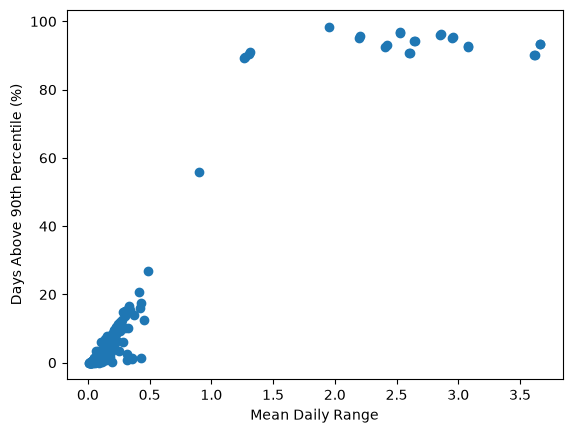

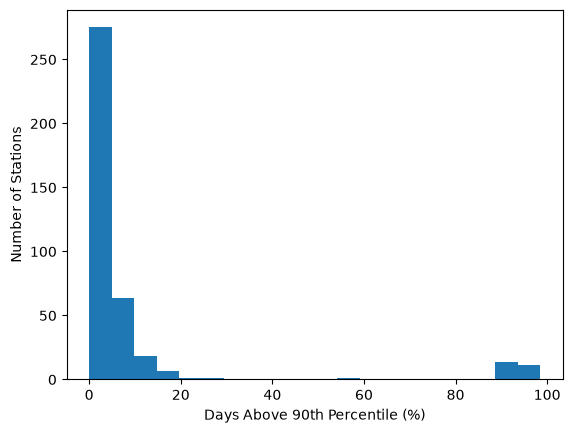

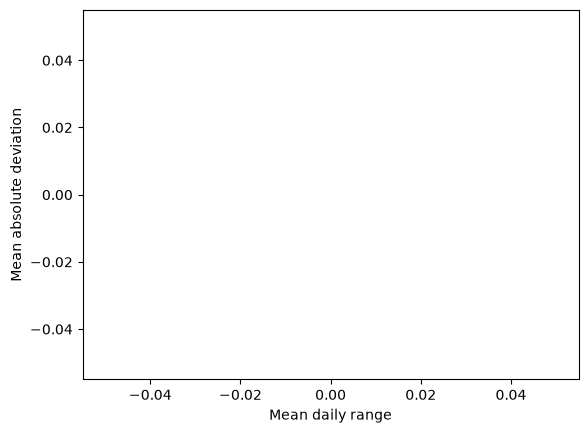

In [31]:
plt.scatter(df_features["Mean_Daily_Range"],
            df_features["Percent_Above_90th"])

plt.xlabel("Mean Daily Range")
plt.ylabel("Days Above 90th Percentile (%)")
plt.show()

Q1 = df_features["90th_Daily_Range"].quantile(0.25)
Q3 = df_features["90th_Daily_Range"].quantile(0.75)

IQR = Q3 - Q1


plt.hist(df_features["Percent_Above_90th"], bins=20)
plt.xlabel("Days Above 90th Percentile (%)")
plt.ylabel("Number of Stations")
plt.show()

plt.scatter(df_features["Mean_Daily_Range"],
            df_features["Mean_Absolute_Deviation"])
plt.xlabel("Mean daily range")
plt.ylabel("Mean absolute deviation")

plt.show()

Then we did PCA cluster analysis on it (all adapted from week 3 workshop). we used ????? features (note that we can change this and somehow analyse which ones we need to change)

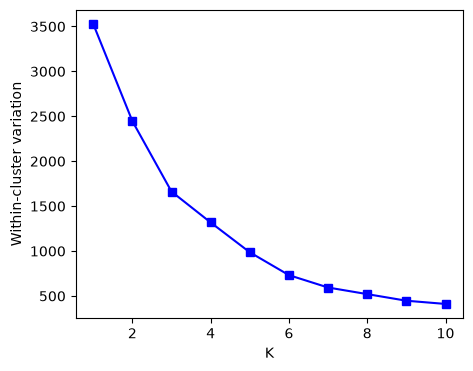

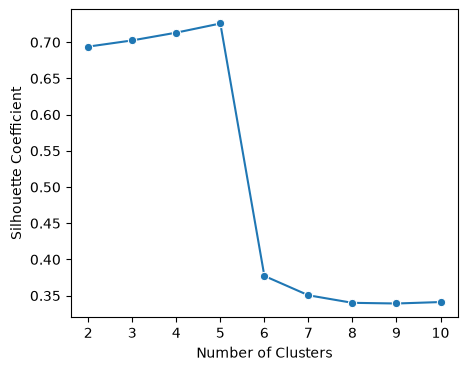

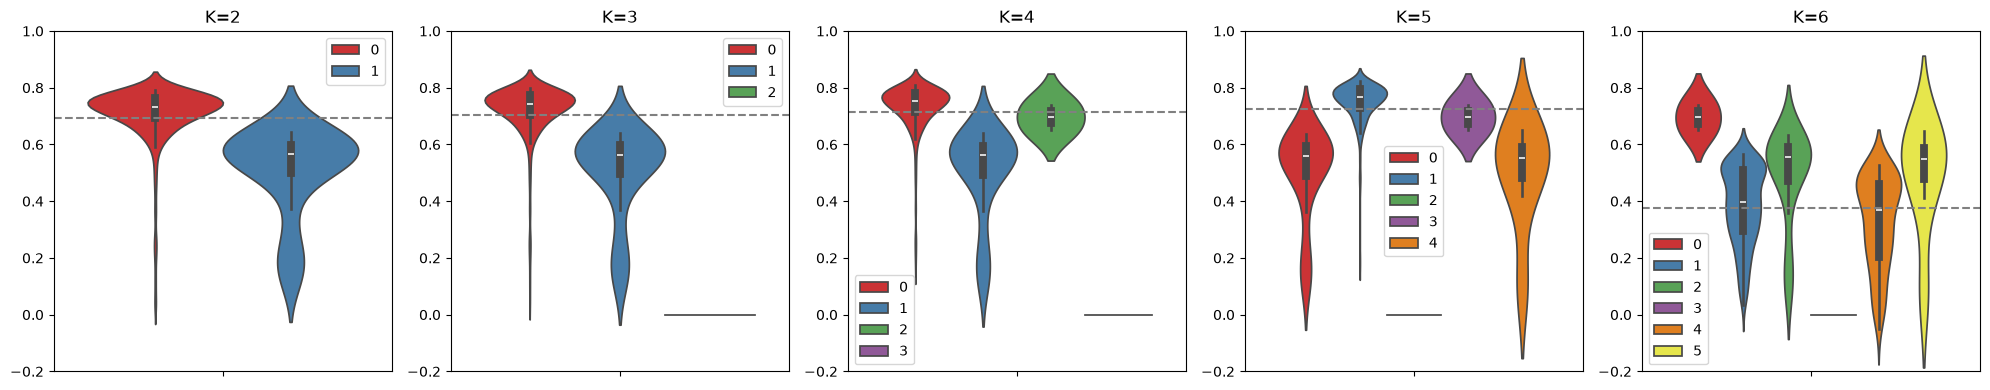

Cluster
1.0    357
0.0     25
4.0      7
3.0      2
2.0      1
Name: count, dtype: int64


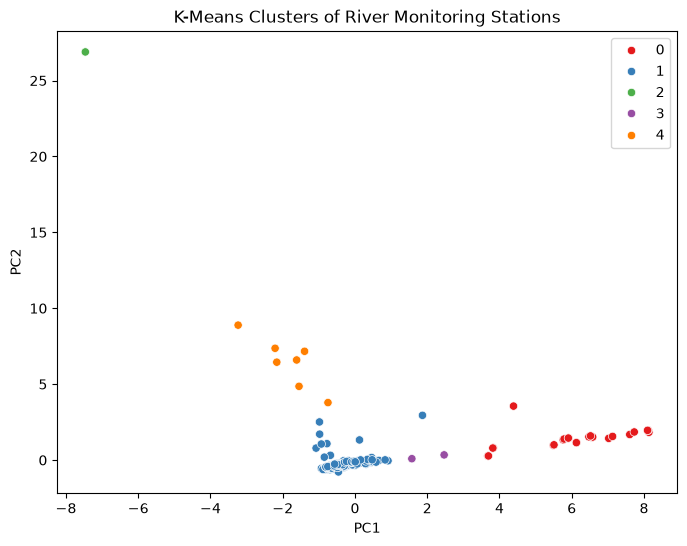

In [23]:
#CLUSTERING WEEK 3 WORKSHOP ADAPTATION

#ex 7 adaptation, preparing the data 
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples

# Choose river behaviour features - NOTE discuss with emma and gabi what features they want to put bc idk
features = [
    "Std_Level",
    "Mean_Daily_Range",
    "Std_Daily_Range",
    "Std_Daily_Change",
    "Mean_Absolute_Deviation",
    "90th_Daily_Range",
    "Percent_Above_90th",
    "Longitude",
    "Latitude"
]

X = df_features[features].dropna()

# Standardise data 
ss = StandardScaler()
Xs = ss.fit_transform(X)

#workshop 5 adaptation, elbow plot
# Workshop Exercise 5: Within-cluster variation

K = np.arange(1, 11)
WCV = np.zeros(K.shape)

for i in range(K.shape[0]):
    kmeans_K = KMeans(n_clusters=K[i], n_init=20, random_state=0).fit(Xs)
    WCV[i] = kmeans_K.inertia_

fig, ax = plt.subplots(1, 1, figsize=(5, 4))
ax.plot(K, WCV, c='b', marker='s')
plt.xlabel('K')
plt.ylabel('Within-cluster variation')
plt.show()

#ex 6 - silhouette analysis
# Workshop Exercise 6: Silhouette scores

K = np.array([2, 3, 4, 5, 6, 7, 8, 9, 10])
silhouette_coeffs = np.zeros(K.shape)

for i in range(K.shape[0]):
    kmeans_K = KMeans(n_clusters=K[i], n_init=20, random_state=0).fit(Xs)
    labs = kmeans_K.predict(Xs)

    silhouette_coeffs[i] = silhouette_score(Xs, labs)

fig, ax = plt.subplots(1, 1, figsize=(5, 4))
sns.lineplot(x=K, y=silhouette_coeffs, marker='o', ax=ax)
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Coefficient')
plt.show()

#ex 6 - violin plots 
# Workshop Exercise 6: Silhouette sample distributions

fig, ax = plt.subplots(1, 5, figsize=(20, 4))

for i in range(5):
    kmeans_K = KMeans(n_clusters=K[i], n_init=20, random_state=0).fit(Xs)
    labs = kmeans_K.labels_
    silhouette_samps = silhouette_samples(Xs, labs)

    sns.violinplot(y=silhouette_samps, hue=labs,
                   ax=ax[i], palette='Set1')

    ax[i].axhline(silhouette_samps.mean(), ls='--', c='gray')
    ax[i].set_title(f'K={K[i]}')
    ax[i].set_ylim([-0.2, 1])

plt.tight_layout()
plt.show()

#k means clustering by ex 12 

kmeans = KMeans(n_clusters=5, n_init=20, random_state=0).fit(Xs)

df_features["Cluster"] = np.nan
df_features.loc[X.index, "Cluster"] = kmeans.labels_

print(df_features["Cluster"].value_counts())

#PCA analysis - adapted from ex 10 and 13
# Workshop Exercises 10 and 13: PCA visualisation

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
scores = pca.fit_transform(Xs)

fig, ax = plt.subplots(1, 1, figsize=(8, 6))

sns.scatterplot(
    x=scores[:, 0],
    y=scores[:, 1],
    hue=kmeans.labels_,
    palette='Set1',
    ax=ax
)

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_title('K-Means Clusters of River Monitoring Stations')

plt.show()

#table of the stats for each of the clusters
df_features.groupby("Cluster")[features].median()

df_map = df_locs.merge(
    df_features[["Observation_ID", "Cluster"]],
    on="Observation_ID"
)

df_map.to_csv("station_clusters.csv", index=False)

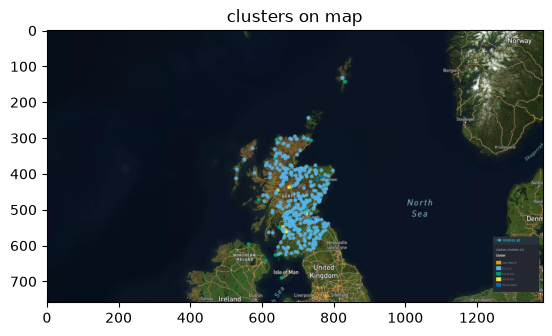

In [26]:
#plotting clusters on a map of scotland 

plt.title("clusters on map")
image = mpimg.imread("clusters_map.png")
plt.imshow(image)
plt.show()

the clustering analysis settled on 5 clusters as shown above on the map. note that we should find a way to convey based on location too perhaps? idk how this is interpretable to the government.